# Crop Recommendation using Decision Tree

## Problem Statement :

### Importing Libraries

In [1]:
import pandas as pd
import numpy as py
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
import warnings
warnings.filterwarnings('ignore')

### Load dataset

In [3]:
crops=pd.read_csv(r"Crop_recommendation.csv")

In [4]:
crops

,N,P,K,temperature,humidity,ph,rainfall,label
0,90,42,43,20.879744,82.002744,6.502985,202.935536,rice
1,85,58,41,21.770462,80.319644,7.038096,226.655537,rice
2,60,55,44,23.004459,82.320763,7.840207,263.964248,rice
3,74,35,40,26.491096,80.158363,6.980401,242.864034,rice
4,78,42,42,20.130175,81.604873,7.628473,262.717340,rice
...,...,...,...,...,...,...,...,...
2195,107,34,32,26.774637,66.413269,6.780064,177.774507,coffee
2196,99,15,27,27.417112,56.636362,6.086922,127.924610,coffee
2197,118,33,30,24.131797,67.225123,6.362608,173.322839,coffee
2198,117,32,34,26.272418,52.127394,6.758793,127.175293,coffee


### Data Cleaning

In [5]:
crops.shape

(2200, 8)

In [6]:
crops.columns

Index(['N', 'P', 'K', 'temperature', 'humidity', 'ph', 'rainfall', 'label'], dtype='object')

In [7]:
crops.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2200 entries, 0 to 2199
Data columns (total 8 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   N            2200 non-null   int64  
 1   P            2200 non-null   int64  
 2   K            2200 non-null   int64  
 3   temperature  2200 non-null   float64
 4   humidity     2200 non-null   float64
 5   ph           2200 non-null   float64
 6   rainfall     2200 non-null   float64
 7   label        2200 non-null   object 
dtypes: float64(4), int64(3), object(1)
memory usage: 137.6+ KB


In [8]:
crops.isnull().sum()

N              0
P              0
K              0
temperature    0
humidity       0
ph             0
rainfall       0
label          0
dtype: int64

In [9]:
crops.duplicated().sum()

np.int64(0)

In [10]:
crops.describe()

,N,P,K,temperature,humidity,ph,rainfall
count,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000,2200.000000
mean,50.551818,53.362727,48.149091,25.616244,71.481779,6.469480,103.463655
std,36.917334,32.985883,50.647931,5.063749,22.263812,0.773938,54.958389
min,0.000000,5.000000,5.000000,8.825675,14.258040,3.504752,20.211267
25%,21.000000,28.000000,20.000000,22.769375,60.261953,5.971693,64.551686
50%,37.000000,51.000000,32.000000,25.598693,80.473146,6.425045,94.867624
75%,84.250000,68.000000,49.000000,28.561654,89.948771,6.923643,124.267508
max,140.000000,145.000000,205.000000,43.675493,99.981876,9.935091,298.560117


In [11]:
crops['label'].unique()

array(['rice', 'maize', 'chickpea', 'kidneybeans', 'pigeonpeas',
       'mothbeans', 'mungbean', 'blackgram', 'lentil', 'pomegranate',
       'banana', 'mango', 'grapes', 'watermelon', 'muskmelon', 'apple',
       'orange', 'papaya', 'coconut', 'cotton', 'jute', 'coffee'],
      dtype=object)

In [12]:
crops['label'].value_counts()

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

### EDA

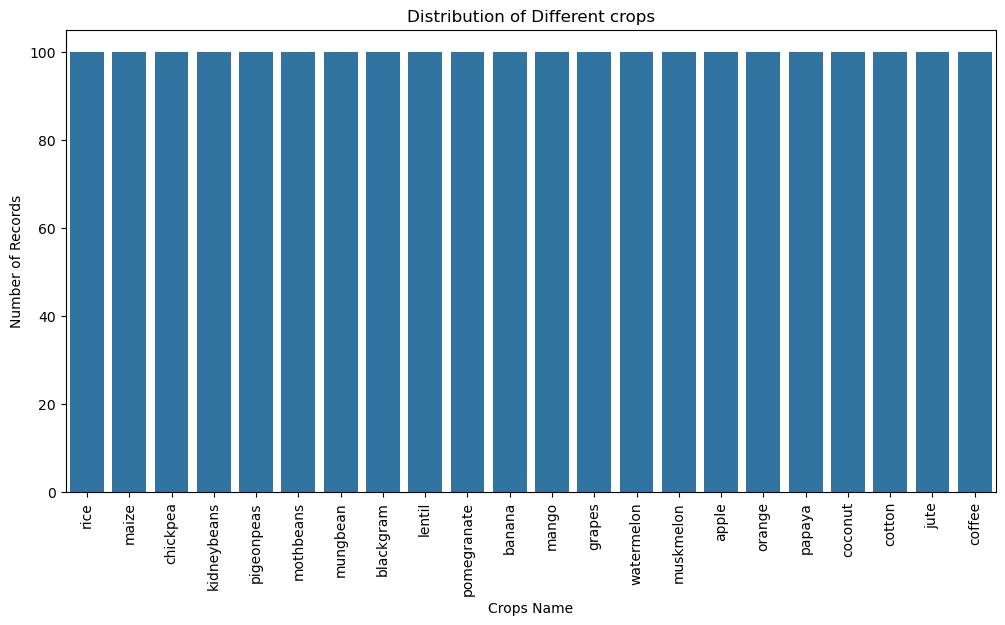

In [13]:
# Distribution of Different crops
plt.figure(figsize=(12,6))
sns.countplot(data=crops, x='label')

plt.title("Distribution of Different crops")
plt.xlabel('Crops Name')
plt.ylabel('Number of Records')
plt.xticks(rotation=90)
plt.show()

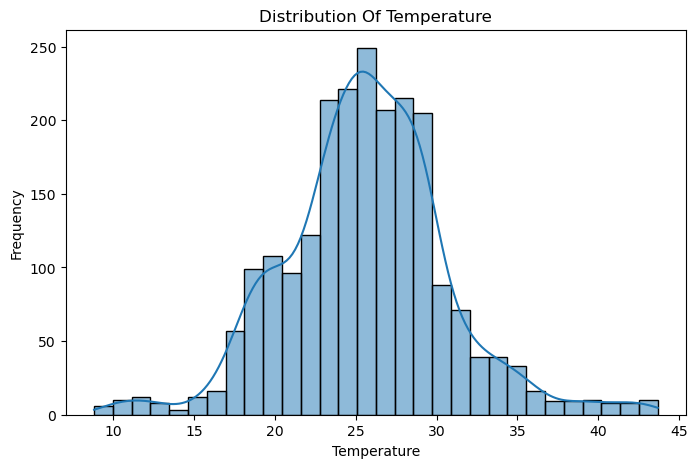

In [14]:
# Distribution Of Temperature
plt.figure(figsize=(8,5))
sns.histplot(data=crops, x='temperature', bins=30, kde=True)

plt.title('Distribution Of Temperature')
plt.xlabel('Temperature')
plt.ylabel('Frequency')
plt.show()

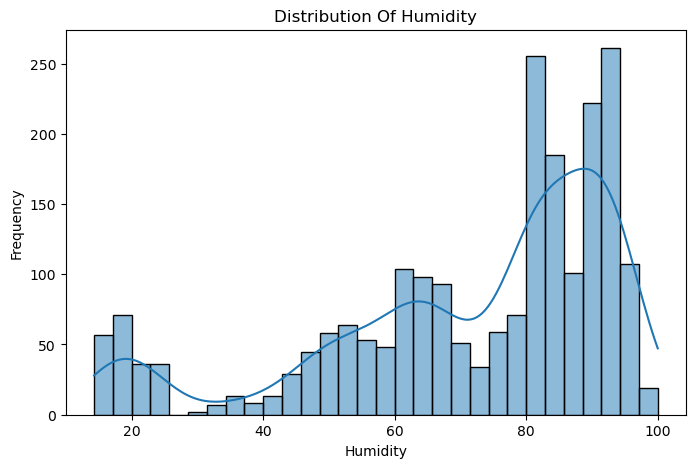

In [15]:
# Distribution Of Humidity
plt.figure(figsize=(8,5))
sns.histplot(data=crops, x='humidity', bins=30, kde=True)

plt.title('Distribution Of Humidity')
plt.xlabel('Humidity')
plt.ylabel('Frequency')
plt.show()

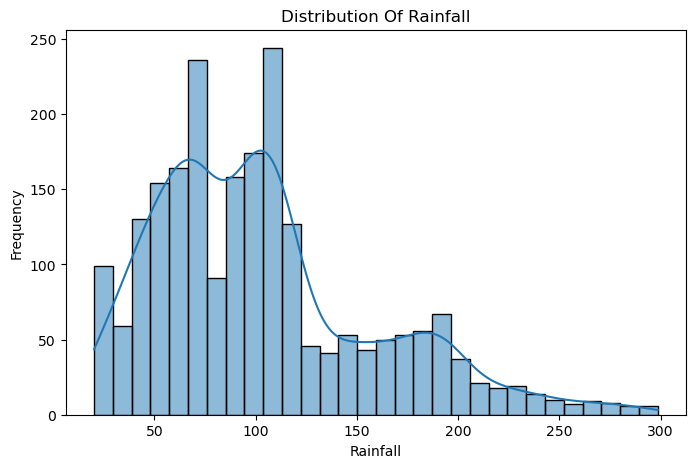

In [16]:
# Distribution Of Rainfall
plt.figure(figsize=(8,5))
sns.histplot(data=crops, x='rainfall', bins=30, kde=True)

plt.title('Distribution Of Rainfall')
plt.xlabel('Rainfall')
plt.ylabel('Frequency')
plt.show()

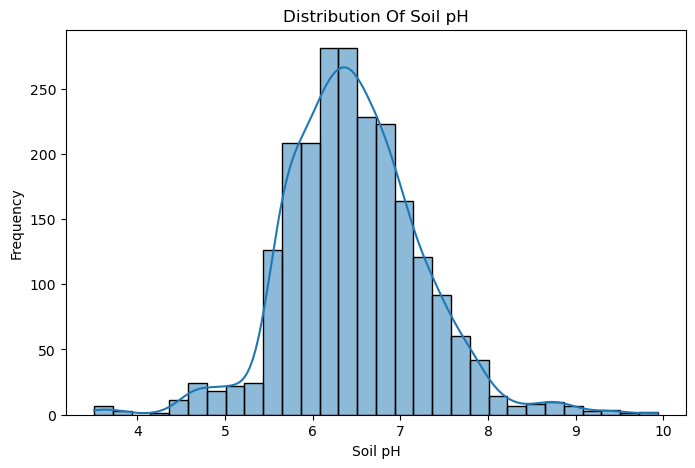

In [17]:
# Distribution Of Soil pH
plt.figure(figsize=(8,5))
sns.histplot(data=crops, x='ph', bins=30, kde=True)

plt.title('Distribution Of Soil pH')
plt.xlabel('Soil pH')
plt.ylabel('Frequency')
plt.show()

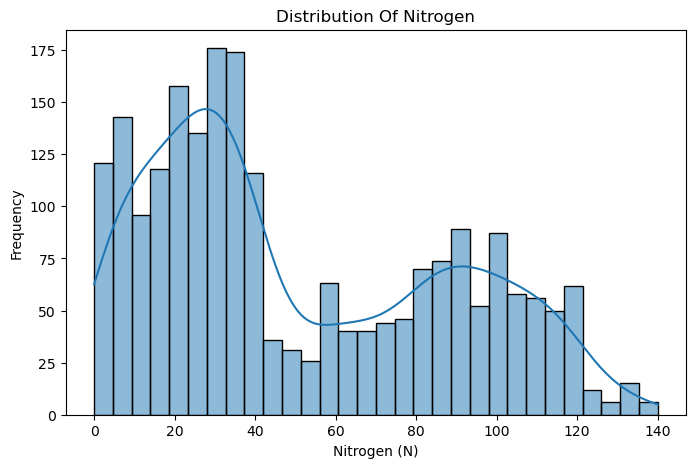

In [18]:
# Distribution Of Nitrogen(N)
plt.figure(figsize=(8,5))
sns.histplot(data=crops, x='N', bins=30, kde=True)

plt.title('Distribution Of Nitrogen')
plt.xlabel('Nitrogen (N)')
plt.ylabel('Frequency')
plt.show()

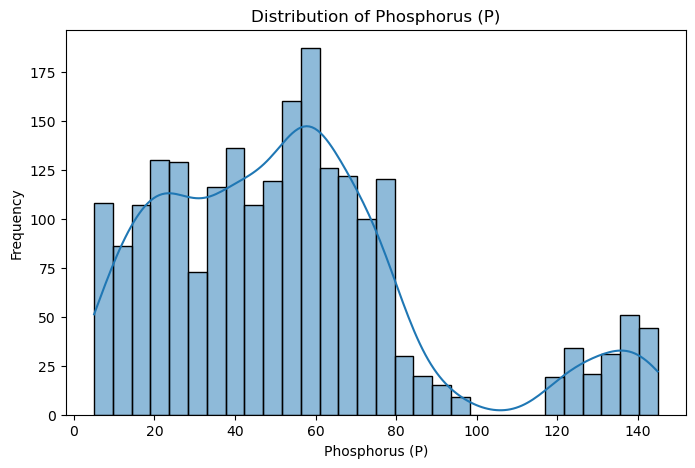

In [19]:
# Graph 7: Distribution of Phosphorus (P)

plt.figure(figsize=(8, 5))
sns.histplot(data=crops, x='P', bins=30, kde=True)

plt.title('Distribution of Phosphorus (P)')
plt.xlabel('Phosphorus (P)')
plt.ylabel('Frequency')
plt.show()

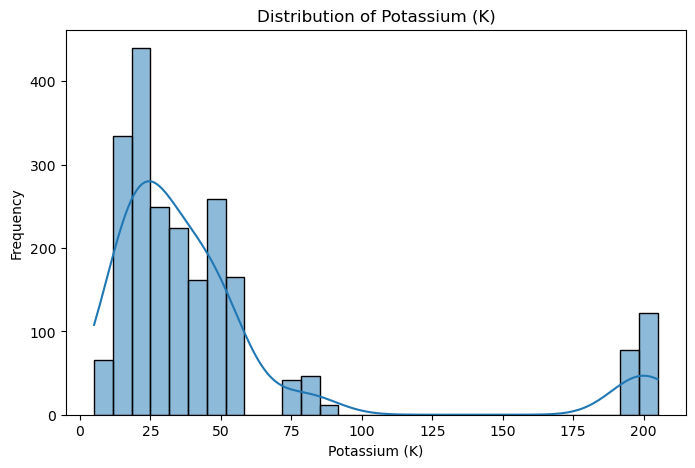

In [20]:
# Graph 8: Distribution of Potassium (K)

plt.figure(figsize=(8, 5))
sns.histplot(data=crops, x='K', bins=30, kde=True)

plt.title('Distribution of Potassium (K)')
plt.xlabel('Potassium (K)')
plt.ylabel('Frequency')
plt.show()

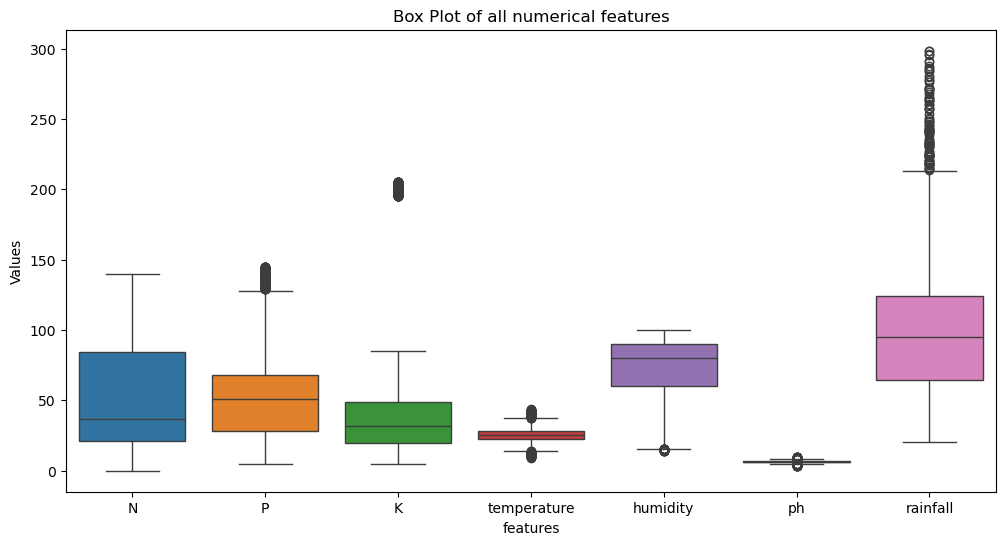

In [21]:
# Box Plot of all numerical features

plt.figure(figsize=(12,6))
sns.boxplot(data=crops[['N','P','K','temperature','humidity','ph','rainfall']])

plt.title('Box Plot of all numerical features')
plt.xlabel('features')
plt.ylabel('Values')
plt.show()

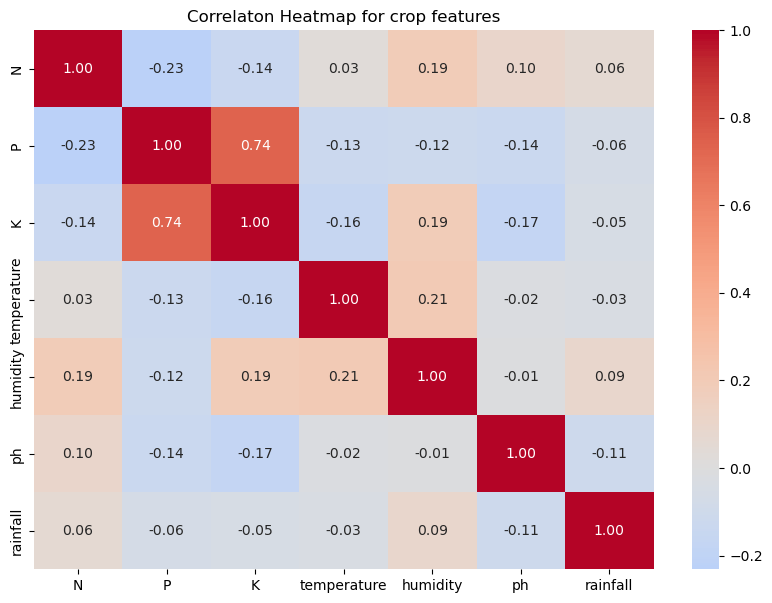

In [22]:
# Correlation Heatmap
plt.figure(figsize=(10,7))
sns.heatmap(crops.select_dtypes(include='number').corr(),
           annot=True,
           cmap='coolwarm',
           center=0,  # exact 0 correlation
           fmt='.2f'
           )
plt.title('Correlaton Heatmap for crop features')
plt.show()

In [23]:
crops.select_dtypes(include='number').corr()


,N,P,K,temperature,humidity,ph,rainfall
N,1.000000,-0.231460,-0.140512,0.026504,0.190688,0.096683,0.059020
P,-0.231460,1.000000,0.736232,-0.127541,-0.118734,-0.138019,-0.063839
K,-0.140512,0.736232,1.000000,-0.160387,0.190859,-0.169503,-0.053461
temperature,0.026504,-0.127541,-0.160387,1.000000,0.205320,-0.017795,-0.030084
humidity,0.190688,-0.118734,0.190859,0.205320,1.000000,-0.008483,0.094423
ph,0.096683,-0.138019,-0.169503,-0.017795,-0.008483,1.000000,-0.109069
rainfall,0.059020,-0.063839,-0.053461,-0.030084,0.094423,-0.109069,1.000000


### Data Preprocessing 

##### **Note:** In Decision Tree classification, we can directly separate the features (X) and target (y) without converting the target variable into numbers because Scikit-learn's `DecisionTreeClassifier` can handle string target labels directly. However, we can also use `LabelEncoder` to convert crop names into numbers.


In [24]:
crops.select_dtypes(include='object').columns


Index(['label'], dtype='object')

In [25]:
crops['label'].value_counts()

label
rice           100
maize          100
jute           100
cotton         100
coconut        100
papaya         100
orange         100
apple          100
muskmelon      100
watermelon     100
grapes         100
mango          100
banana         100
pomegranate    100
lentil         100
blackgram      100
mungbean       100
mothbeans      100
pigeonpeas     100
kidneybeans    100
chickpea       100
coffee         100
Name: count, dtype: int64

In [26]:
from sklearn.preprocessing import LabelEncoder
le= LabelEncoder()

In [27]:
crops[crops.select_dtypes(include='object').columns]=crops[crops.select_dtypes(include='object').columns].apply(le.fit_transform)

In [28]:
crops.select_dtypes(include='object').columns

Index([], dtype='object')

In [29]:
crops['label'].value_counts()

label
20    100
11    100
8     100
6     100
4     100
17    100
16    100
0     100
15    100
21    100
7     100
12    100
1     100
19    100
10    100
2     100
14    100
13    100
18    100
9     100
3     100
5     100
Name: count, dtype: int64

### Separate Features (X) and Target (y)

In [30]:
x = crops.drop('label',axis=1)
y = crops['label']

In [31]:
print(x)
x.shape

        N   P   K  temperature   humidity        ph    rainfall
0      90  42  43    20.879744  82.002744  6.502985  202.935536
1      85  58  41    21.770462  80.319644  7.038096  226.655537
2      60  55  44    23.004459  82.320763  7.840207  263.964248
3      74  35  40    26.491096  80.158363  6.980401  242.864034
4      78  42  42    20.130175  81.604873  7.628473  262.717340
...   ...  ..  ..          ...        ...       ...         ...
2195  107  34  32    26.774637  66.413269  6.780064  177.774507
2196   99  15  27    27.417112  56.636362  6.086922  127.924610
2197  118  33  30    24.131797  67.225123  6.362608  173.322839
2198  117  32  34    26.272418  52.127394  6.758793  127.175293
2199  104  18  30    23.603016  60.396475  6.779833  140.937041

[2200 rows x 7 columns]


(2200, 7)

In [32]:
print(y)
y.shape

0       20
1       20
2       20
3       20
4       20
        ..
2195     5
2196     5
2197     5
2198     5
2199     5
Name: label, Length: 2200, dtype: int64


(2200,)

### Train Test Split

In [33]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [34]:
print('x_train shape : ', x_train.shape)
print('x_test shape : ', x_test.shape)
print('y_train shape : ', y_train.shape)
print('y_test shape : ', y_test.shape)

x_train shape :  (1760, 7)
x_test shape :  (440, 7)
y_train shape :  (1760,)
y_test shape :  (440,)


In [35]:
# save crop label mappimg
original_crops = pd.read_csv("Crop_recommendation.csv")
le.fit(original_crops['label'])

LabelEncoder()

In [36]:
# Display Crop Label Mapping

label_mapping = dict(zip(le.transform(le.classes_), le.classes_))

for number, crop_name in label_mapping.items():
    print(f"{number} = {crop_name}")

0 = apple
1 = banana
2 = blackgram
3 = chickpea
4 = coconut
5 = coffee
6 = cotton
7 = grapes
8 = jute
9 = kidneybeans
10 = lentil
11 = maize
12 = mango
13 = mothbeans
14 = mungbean
15 = muskmelon
16 = orange
17 = papaya
18 = pigeonpeas
19 = pomegranate
20 = rice
21 = watermelon


In [37]:
from sklearn.tree import DecisionTreeClassifier

In [38]:
# importing GridSearchCV for hyperparameter Tunning
from sklearn.model_selection import GridSearchCV

In [39]:
# define Hyperparameters 
param_grid={
    'criterion': ['gini','entropy'],
    'max_depth' : [3,5,7,10,None],
    'min_samples_split' :[2,5,10],
    'min_samples_leaf' : [1,2,4]
}

In [40]:
# create model
dt = DecisionTreeClassifier(random_state=42)

# Apply GridSearchCV for Hyperparameter Tunning
grid_search = GridSearchCV(
    estimator=dt,
    param_grid = param_grid,
    cv = 5,
    scoring = 'accuracy',
    n_jobs = -1,
    verbose = 1
)

In [41]:
# perform hyperparameter on trainning data
grid_search.fit(x_train,y_train)

Fitting 5 folds for each of 90 candidates, totalling 450 fits


,estimator,DecisionTreeC...ndom_state=42)
,param_grid,"{'criterion': ['gini', 'entropy'], 'max_depth': [3, 5, ...], 'min_samples_leaf': [1, 2, ...], 'min_samples_split': [2, 5, ...]}"
,scoring,'accuracy'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,criterion,'gini'


In [42]:
# display best hyperparameters
print('Best Parameters Are : ',grid_search.best_params_)

Best Parameters Are :  {'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 2}


In [43]:
# best cv accuracy
print("Best Cross-validation accuracy : ",grid_search.best_score_)

Best Cross-validation accuracy :  0.9863636363636363


In [44]:
# get best dt model
best_dt = grid_search.best_estimator_
best_dt

,criterion,'gini'
,splitter,'best'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,42
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


### Evaluate The Model

In [45]:
from sklearn.metrics import accuracy_score
y_pred = best_dt.predict(x_test)
test_accuracy = accuracy_score(y_test,y_pred)

print('Test Accuracy : ',test_accuracy)
print('Test Accuracy (%) : ',test_accuracy * 100)

Test Accuracy :  0.9863636363636363
Test Accuracy (%) :  98.63636363636363


In [46]:
y_pred

array([15, 21, 17, 17,  0, 12,  0, 13, 14, 10,  2,  4, 19,  8,  4, 19,  0,
       11, 17, 15,  5, 17, 16, 17,  3,  8, 14, 16, 18, 20, 19, 13,  8, 10,
        8,  2,  8,  3,  3,  9, 17, 12,  2, 11, 14, 11, 18,  4, 15, 11,  2,
        5,  7, 14,  5,  9,  6,  0,  1,  2, 21,  4, 10, 16, 17, 18, 16, 20,
       15, 18, 15,  4,  8,  1,  2, 17,  1,  6, 21, 16,  5,  3, 20, 13, 16,
       12,  5, 13,  2, 19, 11, 13,  6, 17, 18, 13,  9,  5,  2, 10,  4, 20,
       16, 15, 21,  9, 21,  1, 18, 13,  1,  8,  6, 19, 18,  3, 11,  4, 19,
       20, 18,  7,  2,  4,  3,  2,  4, 11,  1, 13,  1,  9, 19,  3,  4, 16,
       18,  1,  1,  0,  9, 15, 14, 13,  4,  4,  0,  4,  9,  2, 14, 10, 21,
       14, 18, 18, 18,  9, 11,  8,  3,  0, 16,  6, 20,  4,  7, 10, 21,  7,
        7,  2, 19,  3,  4, 11, 10,  7, 21,  8,  5,  5,  9,  8, 13,  9,  1,
        9,  4, 17, 17, 14, 12, 19, 21,  9, 11,  0,  2,  3,  7,  7,  1,  6,
       20, 19, 14,  1,  8, 14, 11,  3,  3,  3,  0, 20,  9, 17,  5,  2,  9,
       12, 12,  4, 17,  0

### Classification Report

In [47]:
from sklearn.metrics import classification_report
report = classification_report(y_test,
                               y_pred,
                              target_names=le.classes_,
                              output_dict=True)
report_df = pd.DataFrame(report).transpose()

display(report_df.round(2))

,precision,recall,f1-score,support
apple,1.00,1.00,1.00,23.00
banana,1.00,1.00,1.00,21.00
blackgram,0.95,1.00,0.98,20.00
chickpea,1.00,1.00,1.00,26.00
coconut,0.96,1.00,0.98,27.00
coffee,1.00,1.00,1.00,17.00
cotton,1.00,1.00,1.00,17.00
grapes,1.00,1.00,1.00,14.00
jute,0.92,0.96,0.94,23.00
kidneybeans,1.00,1.00,1.00,20.00


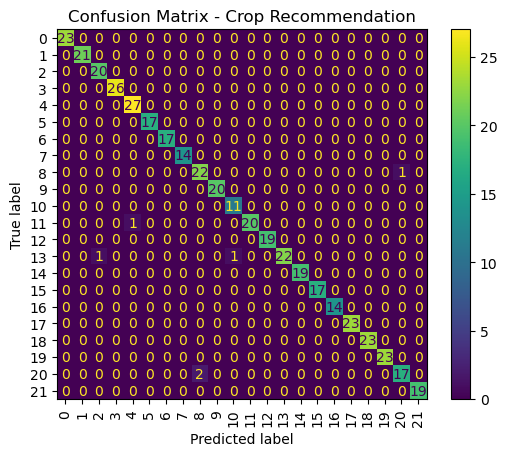

In [48]:
# Confusion Matrix 
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
cm = confusion_matrix(y_test,y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm) 
disp.plot(xticks_rotation=90)
plt.title('Confusion Matrix - Crop Recommendation')
plt.show()

### Understand The matrix
* Understanding the Axes
Y-axis (True label): The actual crop class in the test dataset.
X-axis (Predicted label): The crop class predicted by the model.
The crop labels are encoded as numbers from 0 to 21, representing 22 different crop classes.

* Understanding the Values
Each cell shows the number of records for a particular combination of actual and predicted classes.
For example, the top-left cell contains 23.
Actual class = 0
Predicted class = 0
Number of records = 23
This means that 23 test records actually belonged to class 0, and the model correctly predicted class 0 for all 23 records.

* Diagonal and Non-Diagonal Cells
Diagonal cells
The diagonal runs from the top-left corner to the bottom-right corner.
These cells represent correct predictions because the actual and predicted classes are the same.
Non-diagonal cells
Cells outside the diagonal represent incorrect predictions because the actual and predicted classes differ.
For example, the cell at actual class 8 and predicted class 20 contains 1. This means one record from actual class 8 was incorrectly predicted as class 20.

* Results of Our Model
Total test records: 440
Correct predictions: 434
Incorrect predictions: 6
Test accuracy: approximately 98.64%
The model correctly classified 434 out of 440 test records.

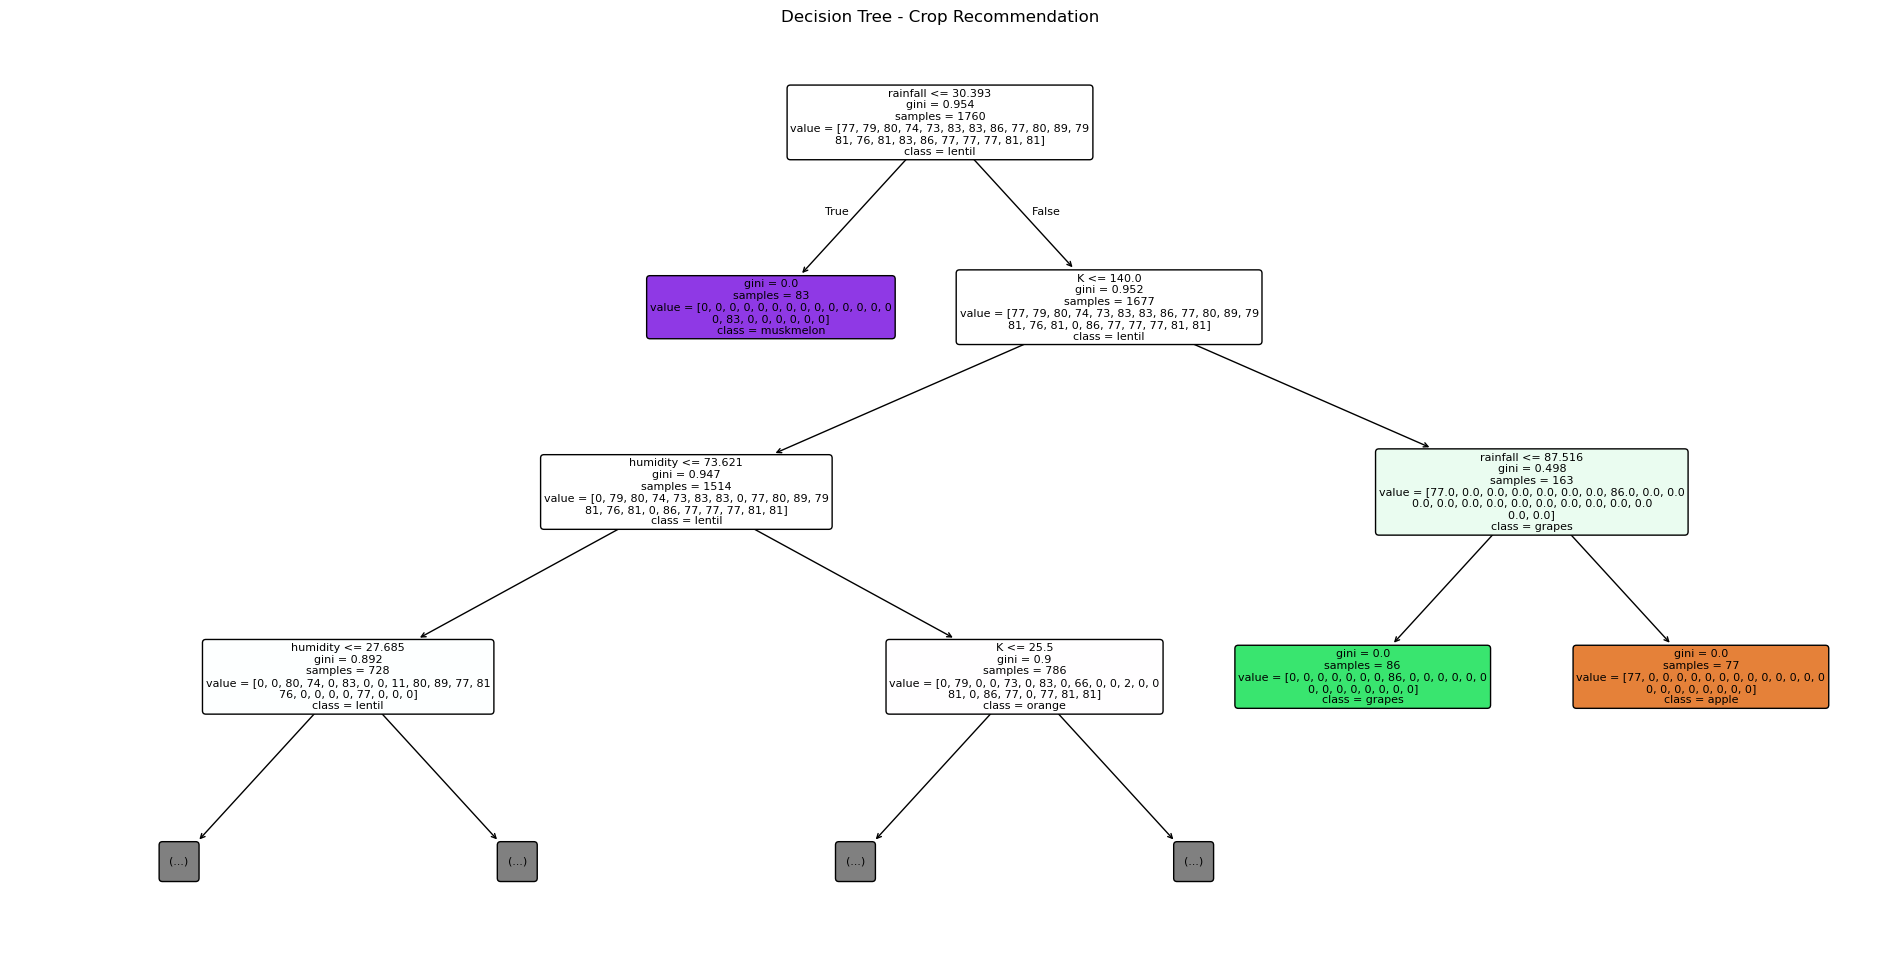

In [49]:
# Visualize the best decision tree
from sklearn.tree import plot_tree

plt.figure(figsize=(24,12))

plot_tree(
    best_dt,
    feature_names=x.columns,
    class_names=le.classes_,
    filled=True,
    rounded=True,
    fontsize=8,
    max_depth=3,
    node_ids=False
)
plt.title('Decision Tree - Crop Recommendation')
plt.show()

### Understand the DT
 *Root Node: The first node containing all training records. In our graph, it has 1,760 samples.
 *Splitting Condition: Conditions such as rainfall <= 30.393 divide records into two branches.
 *Left Branch (True): Records that satisfy the condition move to the left child.
 *Right Branch (False): Records that do not satisfy the condition move to the right child.
 *Gini Impurity: Measures how mixed the crop classes are. Gini = 0 means the node contains only one class.
 *Samples: Number of training records reaching a node.
 *Value: Number of records belonging to each encoded crop class.
 *Class: The most frequent crop class at that node, such as lentil or muskmelon.
 *Leaf Node: The final node that provides the crop prediction.
 *Colors: Help distinguish crop classes and show how pure or mixed a node is.
 *Hidden Branches: The grey (...) boxes indicate branches omitted from the visualization because max_depth=3 was used.

In [50]:
# check features importance
feature_importance = best_dt.feature_importances_
for feature,importance in zip(x.columns,feature_importance):
    print(f'{feature}:{importance:,.4f}')

N:0.1423
P:0.1614
K:0.1457
temperature:0.0042
humidity:0.1857
ph:0.0070
rainfall:0.3536


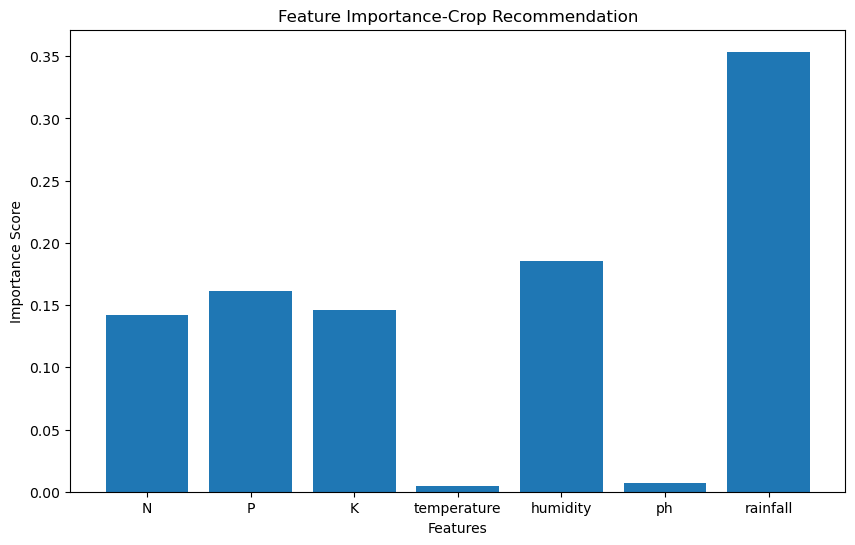

In [51]:
# Visualize feature importance
feature_importance = best_dt.feature_importances_
plt.figure(figsize=(10,6))
plt.bar(x.columns,feature_importance)
plt.xlabel('Features')
plt.ylabel('Importance Score')
plt.title('Feature Importance-Crop Recommendation')
plt.show()

In [52]:
# display feature importance in descending order
importance_df = pd.DataFrame({
    'feature':x.columns,
    'importance': best_dt.feature_importances_
})
importance_df = importance_df.sort_values(
    by='importance',
    ascending= False
)
display(importance_df.round(4))

,feature,importance
6,rainfall,0.3536
4,humidity,0.1857
1,P,0.1614
2,K,0.1457
0,N,0.1423
5,ph,0.0070
3,temperature,0.0042


###
Highest importance score: The feature the trained Decision Tree relies on most for its splits.



Lowest importance score: The feature that contributed the least to the tree's impurity reduction.



Importance = 0: The feature was not used in the trained tree's splits.

### Model Evaluation - Overfitting Check

In [53]:
# checking training accuracy
train_accuracy = best_dt.score(x_train,y_train)

#Get cross validation accuracy
cv_accuracy = grid_search.best_score_

#Check test accuracy
test_accuracy = best_dt.score(x_test,y_test)

# display all accuracies in percentage
print('Training Accuracy :',f'{train_accuracy*100:.2f}%')
print('Cross-Validation Accuracy :',f'{cv_accuracy*100:.2f}%')
print('Testing Accuracy :',f'{test_accuracy*100:.2f}%')

Training Accuracy : 99.77%
Cross-Validation Accuracy : 98.64%
Testing Accuracy : 98.64%


### Conclusion – Overfitting Check

The Decision Tree model achieved a training accuracy of 99.77%, cross-validation accuracy of 98.64%, and testing accuracy of 98.64%. The small difference between training and testing accuracy indicates that the model generalizes(to check how good model predicting for unseen/test data) well to unseen data, with little evidence of significant overfitting.

### Save Trained Model

In [54]:
import joblib
joblib.dump(best_dt,'crop_recommendation_model.pkl')

['crop_recommendation_model.pkl']

In [55]:
# save crop label mapping
joblib.dump(le,'crop_label_encoder.pkl')

['crop_label_encoder.pkl']

#### Load and test saved Model

In [56]:
#load saved dt model
loaded_model= joblib.load('crop_recommendation_model.pkl')

#Load saved labelencoder
loaded_encoder= joblib.load('crop_label_encoder.pkl')

#predict using loaded model
sample_prediction= loaded_model.predict(x_test.iloc[[0]])

# convert the numrical prediction into crop name
predicted_crop= loaded_encoder.inverse_transform(sample_prediction)

print('predicted Crop :',predicted_crop[0])

predicted Crop : muskmelon


In [57]:
# compare actual predicted crop
actual_crop=loaded_encoder.inverse_transform([y_test.iloc[0]])[0]

print("Actual crop : ",actual_crop)
print("Predicted crop : ",predicted_crop[0])

Actual crop :  muskmelon
Predicted crop :  muskmelon
